# 03 — Phase 2: Rare-Class Identification (Entropy Method)

Applies the reference paper's Definitions 1–2 (implemented in
`src/rare_class/entropy.py`) to the **trained baseline model's own
embeddings**, so "which class is rare" is measured, not assumed — and
so we can later check whether fusion (Phase 3) changes which class looks
rare, which would itself be an interesting result.

Assumes `02_baseline_signal_only.ipynb` has been run (needs
`experiments/results/baseline_signal_only_site1v2/best_model.pt`).

In [1]:
from google.colab import drive
drive.mount('/content/drive')
!find /content/drive/MyDrive -maxdepth 3 -iname "*ptbxl*"

Mounted at /content/drive
/content/drive/MyDrive/mm-dg-healthcare-data/ptbxl
/content/drive/MyDrive/mm-dg-healthcare-data/ptbxl.tar


In [2]:
import os
REPO_URL = "https://github.com/Sakina152/mm-dg-healthcare.git"

if not os.path.exists("/content/mm-dg-healthcare"):
    !git clone {REPO_URL} /content/mm-dg-healthcare
%cd /content/mm-dg-healthcare
!pip install -q wfdb transformers pytest PyYAML tqdm scikit-learn pandas matplotlib

Cloning into '/content/mm-dg-healthcare'...
remote: Enumerating objects: 71, done.
remote: Counting objects: 100% (71/71), done.
remote: Compressing objects: 100% (65/65), done.
remote: Total 71 (delta 12), reused 49 (delta 2), pack-reused 0 (from 0)
Receiving objects: 100% (71/71), 1.02 MiB | 4.63 MiB/s, done.
Resolving deltas: 100% (12/12), done.
/content/mm-dg-healthcare
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 163.9/163.9 kB 9.7 MB/s eta 0:00:00


In [3]:
!mkdir -p data/raw
!tar xf /content/drive/MyDrive/mm-dg-healthcare-data/ptbxl.tar -C data/raw
!ls data/raw/ptbxl | head

ptbxl_database.csv
records100
robots.txt
scp_statements.csv


In [4]:
!find /content/drive/MyDrive/mm-dg-healthcare-data -name best_model.pt

/content/drive/MyDrive/mm-dg-healthcare-data/results_backup/baseline_signal_only_site1v2/best_model.pt


In [5]:
!mkdir -p experiments/results/baseline_signal_only_site1v2
!cp "/content/drive/MyDrive/mm-dg-healthcare-data/results_backup/baseline_signal_only_site1v2/best_model.pt" experiments/results/baseline_signal_only_site1v2/best_model.pt
!ls -lh experiments/results/baseline_signal_only_site1v2/

total 856K
-rw------- 1 root root 856K Oct 13 16:47 best_model.pt


In [6]:
%cd /content/mm-dg-healthcare
import torch
import numpy as np
import matplotlib.pyplot as plt

from src.data.ptbxl_dataset import load_ptbxl_metadata, PTBXLDataset, DIAGNOSTIC_SUPERCLASSES
from src.data.domain_split import split_by_domain
from src.models.signal_encoder import SignalEncoder
from src.models.classifier import SignalOnlyClassifier
from src.rare_class.entropy import identify_rare_classes
from src.utils.config import load_config
from src.training.trainer import extract_embeddings
from torch.utils.data import DataLoader

cfg = load_config("configs/baseline_signal_only.yaml")
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

/content/mm-dg-healthcare


## Load the trained baseline and rebuild its train-domain loader

In [7]:
metadata = load_ptbxl_metadata(cfg.data.ptbxl_dir)
split = split_by_domain(metadata, "site", cfg.data.train_sites, cfg.data.test_sites)
label_to_idx = {c: i for i, c in enumerate(DIAGNOSTIC_SUPERCLASSES)}
idx_to_label = {i: c for c, i in label_to_idx.items()}

train_ds = PTBXLDataset(split.train_df, cfg.data.ptbxl_dir, label_to_idx)
train_loader = DataLoader(train_ds, batch_size=64, shuffle=False, num_workers=2)

encoder = SignalEncoder(embed_dim=cfg.model.embed_dim, channel_widths=tuple(cfg.model.channel_widths))
model = SignalOnlyClassifier(encoder, num_classes=len(label_to_idx), embed_dim=cfg.model.embed_dim, hidden_dim=cfg.model.get("hidden_dim")).to(device)
model.load_state_dict(torch.load("experiments/results/baseline_signal_only_site1v2/best_model.pt", map_location=device))
model.eval()
print("Loaded trained baseline.")

Loaded trained baseline.


## Extract embeddings and compute per-class entropy

In [8]:
embeddings, labels = extract_embeddings(model, train_loader, device)
print(f"Embeddings: {embeddings.shape}, labels: {labels.shape}")

result = identify_rare_classes(embeddings, labels, k=cfg.rare_class.k)

print("\nPer-class entropy (theta):")
for cls_idx, theta in sorted(result.class_entropy.items()):
    flag = " <-- RARE" if cls_idx in result.rare_classes else ""
    print(f"  {idx_to_label[cls_idx]:6s} theta={theta:.4f}{flag}")

print(f"\nMean entropy: {result.mean_entropy:.4f}, Std: {result.std_entropy:.4f}")
print(f"Rare classes (Definition 2 threshold = mean +/- 1 std): "
      f"{[idx_to_label[c] for c in result.rare_classes]}")

Embeddings: (6242, 128), labels: (6242,)

Per-class entropy (theta):
  NORM   theta=11.4070 <-- RARE
  MI     theta=9.6440
  STTC   theta=10.1634
  CD     theta=9.9600
  HYP    theta=8.7163 <-- RARE

Mean entropy: 9.9781, Std: 0.8695
Rare classes (Definition 2 threshold = mean +/- 1 std): ['NORM', 'HYP']


In [11]:
import numpy as np, pandas as pd
from sklearn.neighbors import NearestNeighbors

rng = np.random.default_rng(42)
N = 400   # just below the smallest class (HYP = 431)
rows = []
for c in sorted(result.class_entropy):
    e = embeddings[labels == c]
    dists = []
    for _ in range(10):
        sub = e[rng.choice(len(e), N, replace=False)]
        d, _ = NearestNeighbors(n_neighbors=6).fit(sub).kneighbors(sub)
        dists.append(d[:, 1:].mean())
    rows.append({"class": idx_to_label[c], "n": len(e),
                 "theta": round(result.class_entropy[c], 3),
                 "knn_dist_at_n400": round(float(np.mean(dists)), 4)})
pd.DataFrame(rows)

,class,n,theta,knn_dist_at_n400
0,NORM,2775,11.407,1.7135
1,MI,823,9.644,1.8105
2,STTC,1185,10.163,1.7141
3,CD,1028,9.960,2.0729
4,HYP,431,8.716,1.7573


In [12]:
from sklearn.neighbors import NearestNeighbors
import pandas as pd

RARE = 4   # HYP
nn = NearestNeighbors(n_neighbors=11).fit(embeddings)
_, idx = nn.kneighbors(embeddings[labels == RARE])
neigh = pd.Series(labels[idx[:, 1:]].ravel()).map(idx_to_label)   # drop self-match

out = pd.DataFrame({
    "neighbor_share": neigh.value_counts(normalize=True),
    "base_rate": pd.Series(labels).map(idx_to_label).value_counts(normalize=True),
})
out["over_representation"] = (out["neighbor_share"] / out["base_rate"]).round(2)
out.round(3).sort_values("over_representation", ascending=False)

,neighbor_share,base_rate,over_representation
HYP,0.769,0.069,11.14
STTC,0.107,0.190,0.57
MI,0.044,0.132,0.33
NORM,0.063,0.445,0.14
CD,0.016,0.165,0.10


## Visualize

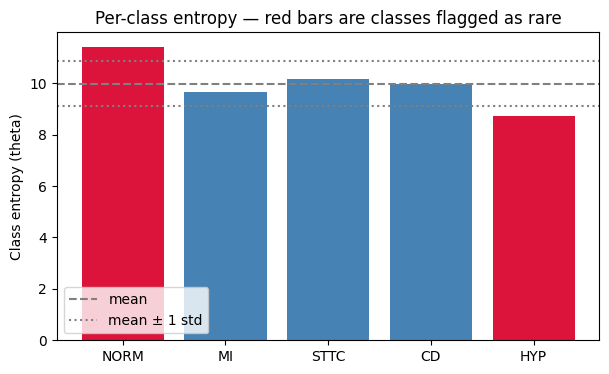

In [9]:
labels_sorted = sorted(result.class_entropy.keys())
thetas = [result.class_entropy[c] for c in labels_sorted]
colors = ["crimson" if c in result.rare_classes else "steelblue" for c in labels_sorted]

plt.figure(figsize=(7, 4))
plt.bar([idx_to_label[c] for c in labels_sorted], thetas, color=colors)
plt.axhline(result.mean_entropy, color="gray", linestyle="--", label="mean")
plt.axhline(result.mean_entropy + result.std_entropy, color="gray", linestyle=":", label="mean ± 1 std")
plt.axhline(result.mean_entropy - result.std_entropy, color="gray", linestyle=":")
plt.ylabel("Class entropy (theta)")
plt.title("Per-class entropy — red bars are classes flagged as rare")
plt.legend()
plt.show()

## Compare against raw class frequency

Worth checking: is the "rare" class by entropy the same as the class with
fewest raw examples? If not, that's exactly the reference paper's point —
rarity isn't just about count, it's about how spread out/inconsistent the
class's representations are.

In [10]:
counts = np.bincount(labels, minlength=len(label_to_idx))
for i, c in enumerate(counts):
    print(f"{idx_to_label[i]:6s} n={c:5d}  theta={result.class_entropy.get(i, float('nan')):.4f}")

NORM   n= 2775  theta=11.4070
MI     n=  823  theta=9.6440
STTC   n= 1185  theta=10.1634
CD     n= 1028  theta=9.9600
HYP    n=  431  theta=8.7163


In [13]:
import pandas as pd, numpy as np, torch
from sklearn.metrics import confusion_matrix
from torch.utils.data import DataLoader

test_ds = PTBXLDataset(split.test_df, cfg.data.ptbxl_dir, label_to_idx)
test_loader = DataLoader(test_ds, batch_size=64, shuffle=False, num_workers=2)
preds, ys = [], []
with torch.no_grad():
    for b in test_loader:
        preds.append(model(b["signal"].to(device)).argmax(1).cpu().numpy())
        ys.append(b["label"].numpy())
names = [idx_to_label[i] for i in range(5)]
cm = confusion_matrix(np.concatenate(ys), np.concatenate(preds), labels=range(5), normalize="true")
pd.DataFrame(cm, index=[f"true {n}" for n in names], columns=[f"pred {n}" for n in names]).round(2)

,pred NORM,pred MI,pred STTC,pred CD,pred HYP
true NORM,0.91,0.01,0.06,0.01,0.01
true MI,0.29,0.33,0.21,0.14,0.03
true STTC,0.22,0.06,0.67,0.03,0.03
true CD,0.33,0.08,0.13,0.46,0.01
true HYP,0.34,0.10,0.26,0.03,0.26


In [14]:
cols = ["age", "sex", "height", "weight"]
print("Missing fraction overall:\n", metadata[cols].isna().mean().round(2))
print("\nMissing fraction, site 1 vs site 2:\n",
      metadata[metadata.site.isin([1, 2])].groupby("site")[cols].apply(lambda d: d.isna().mean()).round(2))
print("\nMean age and sex by class:\n",
      metadata.groupby("superclass")[["age", "sex"]].mean().round(2))
print("\nMean age by site 1 vs 2:\n",
      metadata[metadata.site.isin([1, 2])].groupby("site")["age"].mean().round(1))

Missing fraction overall:
 age       0.00
sex       0.00
height    0.68
weight    0.56
dtype: float64

Missing fraction, site 1 vs site 2:
       age  sex  height  weight
site                          
1     0.0  0.0    0.05    0.08
2     0.0  0.0    0.98    0.98

Mean age and sex by class:
               age   sex
superclass             
CD          71.15  0.40
HYP         66.52  0.43
MI          69.86  0.37
NORM        52.90  0.54
STTC        70.28  0.55

Mean age by site 1 vs 2:
 site
1    69.6
2    70.8
Name: age, dtype: float64


## Next steps (not yet built)

This notebook establishes *which class is rare* and confirms the entropy
math (already unit-tested in `tests/test_entropy.py`) runs correctly on
real learned embeddings. Phases 3–6 (multimodal fusion, missing-modality
robustness, full ablation) are scaffolded in `src/models/fusion.py`,
`src/models/text_encoder.py`, and `src/training/modality_dropout.py` —
see each file's docstring for the implementation plan, and
`notebooks/04_multimodal_fusion.ipynb` onward for their placeholders.